# Histogram reproduction — Asimov vs median of toys

**What this notebook does.** Reproduces the histogram-analysis half of the NSBI-shortcomings study.
It bins the off-shell $gg\to ZZ\to 4\ell$ events in $m_{4\ell}$, builds the extended-Poisson
negative-log-likelihood (NLL) scan in the signal strength $\mu$ for **(a)** the Asimov dataset and
**(b)** 200 toy pseudo-experiments, and checks — at 1, 10, 100 and 1000 fb$^{-1}$ — whether the
Asimov scan equals the median of the toys (the *Asimov property*).

**Result.** The property holds at every luminosity: the median-of-toys curve sits on top of the
Asimov curve (see *Main result* below). This is the histogram baseline the NSBI analysis is compared
against — NSBI is expected to *break* this at 1–10 fb$^{-1}$.

**How to use it.** Run top to bottom (~1–2 min inside the Apptainer container). Everything you would
normally tweak is in the **Parameters** cell (luminosities, binning, number of toys, $\mu$ grid),
and the plotting cells are separate from the analysis so you can restyle the figures and re-run just
those cells.

> **Engine.** This notebook only *calls* the analysis code in the `asimov-aymptotics-check` sub-repo
> (`physics`, `stats` packages) — it does not reimplement any physics. Companion write-up:
> `docs/hist-reproduction.md`; theory primer: `docs/notes/sbi_foundations.md`.
>
> **Run it** from the container: `apptainer exec --nv --env PYTHONNOUSERSITE=1 asimov-aymptotics-check/ml4fp-sbi-tutorial.sif jupyter lab` (or execute headlessly). `PYTHONNOUSERSITE=1` keeps stray `~/.local` packages from shadowing the container.

## 1. Imports and engine path

In [1]:
import os, sys, json
import numpy as np
import torch
import hist
import matplotlib.pyplot as plt

# Point Python at Tei's analysis packages (physics/, stats/) inside the sub-repo.
ROOT    = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
SUBREPO = os.path.join(ROOT, 'asimov-aymptotics-check')
if SUBREPO not in sys.path:
    sys.path.insert(0, SUBREPO)

from physics.simulation import mcfm, toys           # data loader + toy generator (the engine)
from physics.hstar import sigstr                     # per-event mu reweighting
from stats.binned import poisson_log_likelihood_scan, poisson_log_likelihood_scan_toys

torch.set_default_dtype(torch.float32)
print('engine:', SUBREPO)

engine: /project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check


## 2. Parameters

Everything you might want to change lives here. Defaults reproduce the committed study.

In [2]:
# ---- adjust here --------------------------------------------------------------
DATA_DIR = os.environ.get('DATASET_DIR', os.path.join(ROOT, 'data/zz4l/ggzz4l_sm'))
LUMIS    = [1., 10., 100., 1000.]         # luminosities to scan [fb^-1]
N_ROWS   = int(3e5)                        # events read from the SBI CSV
N_TOYS   = 200                             # toy pseudo-experiments per luminosity
SEED     = 42                              # toy random seed
MU_SCAN  = torch.linspace(0.0, 4.0, 101)   # signal-strength grid
N_BINS, M4L_LO, M4L_HI = 10, 180, 1000     # m4l log-binning [GeV]
# -------------------------------------------------------------------------------

m4l_axis = hist.axis.Regular(N_BINS, M4L_LO, M4L_HI, transform=hist.axis.transform.log)
features_4l = ['l1_pt','l1_eta','l1_phi','l1_energy','l2_pt','l2_eta','l2_phi','l2_energy',
               'l3_pt','l3_eta','l3_phi','l3_energy','l4_pt','l4_eta','l4_phi','l4_energy','4l_mass']
mu_np = MU_SCAN.numpy()

## 3. Load the events (once)

The cross-section JSON stores `[flavour-count, k-factor, sigma_raw]` per component; `np.prod` gives
the usable cross-section in fb, and `mcfm.from_csv` normalises the sum of event weights to it.
**Luminosity is not applied here** — it enters only as a multiplier at histogram-fill time, so the
same events serve every luminosity in `LUMIS`.

In [3]:
with open(os.path.join(DATA_DIR, 'ggzz4l_xs.json')) as f:
    xs = json.load(f)
xs_sbi_sm = np.prod(xs['sbi'])

events_sbi = mcfm.from_csv(file_path=os.path.join(DATA_DIR, 'ggzz4l_sbi.csv'),
                           kinematics=features_4l, cross_section=xs_sbi_sm, n_rows=N_ROWS)
m4l = events_sbi.kinematics['4l_mass'].values
print(f'loaded {len(m4l):,} events;  sum of SM weights = {events_sbi.weights.sum():.4f} fb  (= cross-section)')

loaded 300,000 events;  sum of SM weights = 5.6565 fb  (= cross-section)


## 4. Per-event weights (luminosity-independent)

`sigstr.scale` reweights the single SBI sample to any signal strength $\mu$ via the stored matrix
elements: $w(\mu)=w_{\rm sm}\,(\mu\,{\rm msq}_S+\sqrt{\mu}\,{\rm msq}_I+{\rm msq}_B)/{\rm msq}_{\rm SBI}$.
We compute the SM point ($\mu=1$) and the whole $\mu$ grid once. Because a histogram bin's content
is *linear* in the weights, the Asimov and expected-scan histograms at luminosity $L$ are simply
$L\times$ their unit-luminosity values — so the expensive 101-point fill is done a single time.

In [4]:
w_sm,   _ = sigstr.scale(events_sbi, signal_strength=1.0,     ignore_interference=False)   # (N,)
w_scan, _ = sigstr.scale(events_sbi, signal_strength=MU_SCAN, ignore_interference=False)   # (N, 101)

def fill(weights):
    h = hist.Hist(m4l_axis)
    h.fill(m4l, weight=np.asarray(weights))
    return h.values()

nu_asimov_unit = fill(w_sm)                                                          # (10,)  at L=1
nu_exp_unit    = np.stack([fill(w_scan[:, m]) for m in range(w_scan.shape[1])], 1)   # (10,101) at L=1
print('unit-luminosity Asimov m4l histogram (events / fb):')
print(np.round(nu_asimov_unit, 4))

unit-luminosity Asimov m4l histogram (events / fb):
[1.8545 1.7091 1.0148 0.5328 0.2759 0.1406 0.0723 0.0322 0.0154 0.0059]


## 5. Luminosity loop: Asimov + toys + NLL scans

For each luminosity $L$: scale the (linear) Asimov and expected histograms by $L$; throw `N_TOYS`
Poisson pseudo-datasets ($w_{\rm toy}\sim{\rm Poisson}(w_{\rm sm}L)$ per event) and histogram them;
then evaluate the binned extended-Poisson NLL scan
$$\mathrm{NLL}(\mu) = -2\sum_{\rm bins}\big[\,n\,\ln\nu(\mu)-\nu(\mu)-\ln n!\,\big].$$
The rate term $-\nu(\mu)$ is included automatically (the histogram likelihood is a full extended
likelihood), which is exactly the piece the NSBI notebook is missing.

In [5]:
results = {}
for L in LUMIS:
    nu_asimov = nu_asimov_unit * L                                                    # (10,)
    nu_exp    = nu_exp_unit * L                                                        # (10,101)

    nu_toys    = toys.generate(w_sm * L, n_toys=N_TOYS, random_state=SEED)             # (N_TOYS, N)
    n_obs_toys = torch.tensor(np.stack([fill(nu_toys[i, :]) for i in range(N_TOYS)], 1))  # (10,N_TOYS)

    nll_asimov = -2 * poisson_log_likelihood_scan(nu_asimov, nu_exp)                   # (101,)
    nll_toys   = -2 * poisson_log_likelihood_scan_toys(n_obs_toys, nu_exp)             # (101,N_TOYS)
    results[L] = dict(nll_asimov=nll_asimov, nll_toys=nll_toys, nu_asimov=nu_asimov)
    print(f'{L:>7.0f} fb^-1 :  Asimov mu_hat = {MU_SCAN[torch.argmin(nll_asimov)]:.3f}')

/project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check/physics/simulation/toys.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights = torch.tensor(nu, dtype=torch.float64)


      1 fb^-1 :  Asimov mu_hat = 1.000


     10 fb^-1 :  Asimov mu_hat = 1.000


    100 fb^-1 :  Asimov mu_hat = 1.000


   1000 fb^-1 :  Asimov mu_hat = 1.000


## 6. Main result — Asimov vs median of toys

One panel per luminosity. **Solid** = median of the toy scans; **dashed** = Asimov; band = 16–84%
spread of the (min-subtracted) toy curves; dotted line = the $-2\Delta\ln L=1$ (68%) level.
*The Asimov property holds where the solid curve sits on the dashed curve.* This is the plotting
cell — restyle freely and re-run just this cell.

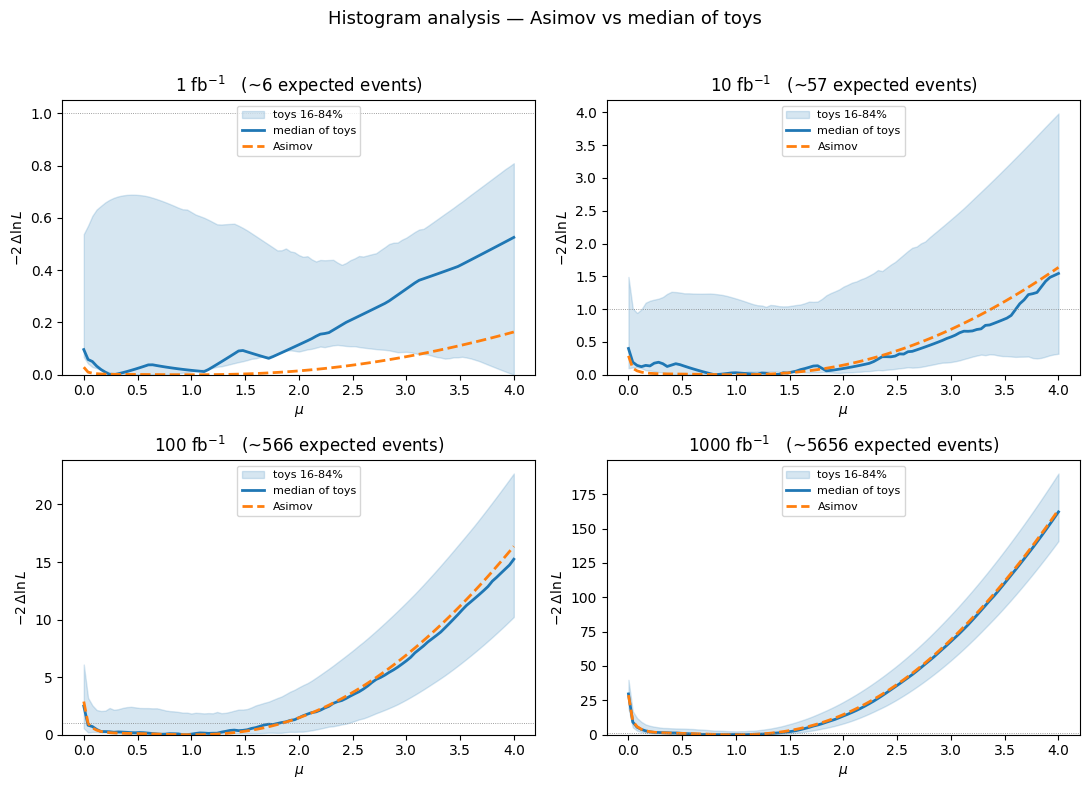

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, L in zip(axes.flat, LUMIS):
    r    = results[L]
    da   = (r['nll_asimov'] - r['nll_asimov'].min()).numpy()
    tm   = r['nll_toys'] - r['nll_toys'].min(dim=0).values          # per-toy min-subtracted
    med  = torch.median(r['nll_toys'], dim=1).values
    dmed = (med - med.min()).numpy()
    lo, hi = torch.quantile(tm, torch.tensor([0.16, 0.84]), dim=1).numpy()

    ax.fill_between(mu_np, lo, hi, alpha=0.18, color='C0', label='toys 16-84%')
    ax.plot(mu_np, dmed, '-',  color='C0', lw=2, label='median of toys')
    ax.plot(mu_np, da,   '--', color='C1', lw=2, label='Asimov')
    ax.axhline(1.0, color='grey', lw=0.6, ls=':')
    ax.set_title(f'{L:.0f} fb$^{{-1}}$   (~{5.656*L:.0f} expected events)')
    ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$-2\,\Delta\ln L$'); ax.set_ylim(bottom=0)
    ax.legend(fontsize=8, loc='upper center')
fig.suptitle('Histogram analysis — Asimov vs median of toys', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 7. Diagnostics at the lowest luminosity

Left: the Asimov $m_{4\ell}$ spectrum (the steeply falling off-shell tail). Right: all 200 individual
toy scans (thin) with the Asimov overlaid — this is what the median in the panel above summarises.

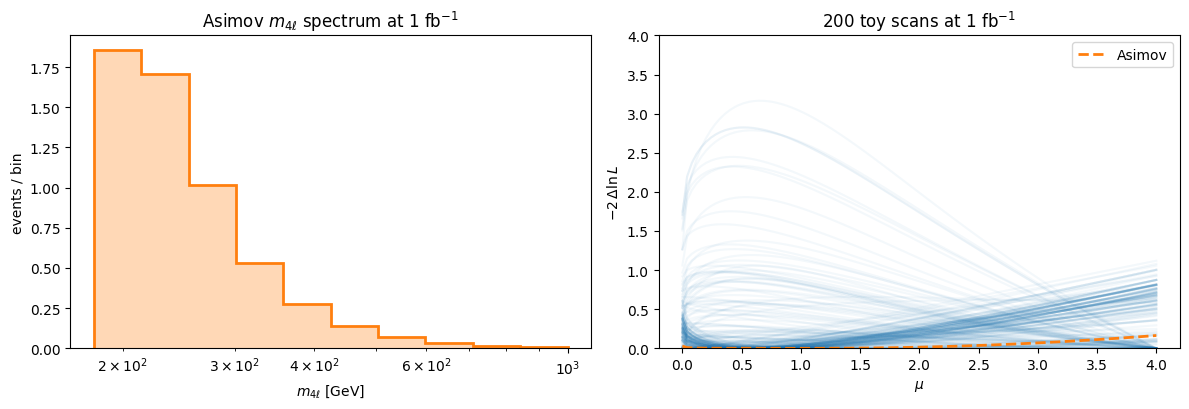

In [7]:
L0 = LUMIS[0]; r = results[L0]; edges = m4l_axis.edges
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.2))
axL.stairs(r['nu_asimov'], edges, color='C1', lw=2, fill=True, alpha=0.3)
axL.stairs(r['nu_asimov'], edges, color='C1', lw=2)
axL.set_xscale('log'); axL.set_xlabel(r'$m_{4\ell}$ [GeV]'); axL.set_ylabel('events / bin')
axL.set_title(f'Asimov $m_{{4\ell}}$ spectrum at {L0:.0f} fb$^{{-1}}$')
for i in range(r['nll_toys'].shape[1]):
    axR.plot(mu_np, (r['nll_toys'][:, i] - r['nll_toys'][:, i].min()).numpy(), color='C0', alpha=0.05)
axR.plot(mu_np, (r['nll_asimov'] - r['nll_asimov'].min()).numpy(), '--', color='C1', lw=2, label='Asimov')
axR.set_xlabel(r'$\mu$'); axR.set_ylabel(r'$-2\,\Delta\ln L$'); axR.set_ylim(0, 4)
axR.set_title(f'200 toy scans at {L0:.0f} fb$^{{-1}}$'); axR.legend()
fig.tight_layout(); plt.show()

## 8. Quantitative summary

1σ half-widths from the $-2\Delta\ln L=1$ crossings (where the interval closes inside the $\mu$
window). `ratio` = width(median) / width(Asimov); ~1 means the Asimov property holds. At 1–10
fb$^{-1}$ the curves are too shallow for the interval to close in $[0,4]$ (marked `nan`) — widen
`MU_SCAN` if you want a number there.

In [8]:
def interval(nll):
    d = (nll - nll.min()).numpy(); g = mu_np; i = int(np.argmin(d))
    lo = np.interp(1.0, d[:i+1][::-1], g[:i+1][::-1]) if i > 0 and d[:i+1].max() >= 1 else np.nan
    hi = np.interp(1.0, d[i:], g[i:]) if i < len(d)-1 and d[i:].max() >= 1 else np.nan
    return g[i], lo, hi

print(f"{'lumi':>8} {'mu_hat_A':>9} {'width_A':>9} {'width_med':>10} {'ratio':>7}")
for L in LUMIS:
    r = results[L]
    _, la, ha = interval(r['nll_asimov'])
    mh, lm, hm = interval(torch.median(r['nll_toys'], dim=1).values)
    wa, wm = ha - la, hm - lm
    ratio = wm / wa if (wa == wa and wm == wm) else float('nan')
    mu_hat = MU_SCAN[torch.argmin(r['nll_asimov'])].item()
    print(f"{L:>8.0f} {mu_hat:>9.3f} {wa:>9.3f} {wm:>10.3f} {ratio:>7.3f}")

    lumi  mu_hat_A   width_A  width_med   ratio
       1     1.000       nan        nan     nan
      10     1.000       nan        nan     nan
     100     1.000     1.805      1.777   0.985
    1000     1.000     0.805      0.848   1.054


## 9. Save scan tensors

Written to the gitignored `output/hist/lumi_<L>/` (the `.pt` triple the write-up references). Re-run
freely; these are regenerated each time.

In [9]:
OUT = os.path.join(ROOT, 'output', 'hist')
for L in LUMIS:
    d = os.path.join(OUT, f'lumi_{int(L)}'); os.makedirs(d, exist_ok=True)
    torch.save(MU_SCAN,                 os.path.join(d, 'poi_scan.pt'))
    torch.save(results[L]['nll_asimov'], os.path.join(d, 'nll_scan_asimov.pt'))
    torch.save(results[L]['nll_toys'],   os.path.join(d, 'nll_scan_toys.pt'))
print('saved scans under', OUT)

saved scans under /project/atlas/Users/mfernand/SBI_shortcomings/output/hist


## What this shows

- **Asimov ≈ median(toys) at every luminosity** — the histogram analysis satisfies the Asimov
  property, *including* the 1–10 fb$^{-1}$ regime where NSBI is expected to fail. This is the baseline.
- Where the 1σ interval closes in the window (100 & 1000 fb$^{-1}$) the widths agree to a few percent;
  at 1–10 fb$^{-1}$ the curves are too shallow (~6 / 57 events) for the interval to close — the curves
  still overlap, but the width metric is undefined there.
- Asimov best fit $\hat\mu = 1.000$ everywhere (the full extended likelihood recovers the injected
  value) — contrast the NSBI shape-only scan, whose Asimov $\hat\mu = 0.92$ at 300 fb$^{-1}$.

**Next:** the NSBI counterpart of this notebook (needs the CARL networks — see `docs/nsbi-repro-prep.md`).